In [1]:
from som_rl.eval.rollout import run_episode, save_run
from som_rl.eval.plots import summary_dict, save_all_plots, plot_trace, plot_heatmaps, plot_bin_snapshots
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import os
import numpy as np

# Your classes (adjust import paths to your repo)
from som_rl.som.som_backend import SOMControl, SOMBackendConfig
from som_rl.env.env import SOMBinningEnv, SOMEnvConfig

from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych


In [2]:
# Cell 1 — load data (paths)
DATA = "data"

NPZ_PATH   = os.path.join(DATA, "correlations_dl","npairs_compact.npz")
NODES_INIT = os.path.join(DATA, "nodes_labels_initial_fc_200_ext.npy")
NODE_PHOTO = os.path.join(DATA, "node_indices_fc.npy")
REF_LABELS = os.path.join(DATA, "reference_labels_fc_fc.npy")

npz = np.load(NPZ_PATH)
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

# Drop last dimension for compatibility
dd = dd.squeeze(-1)
dr = dr.squeeze(-1)
rd = rd.squeeze(-1)
rr = rr.squeeze(-1)

initial_node_bins   = np.load(NODES_INIT).astype(np.int32)
node_indices_photo  = np.load(NODE_PHOTO).astype(np.int64)
reference_labels    = np.load(REF_LABELS).astype(np.int32)

print("dd shape:", dd.shape, "dtype:", dd.dtype)
print("initial bins:", initial_node_bins.shape, initial_node_bins.min(), initial_node_bins.max())
print("node_indices_photo:", node_indices_photo.shape, node_indices_photo.min(), node_indices_photo.max())
print("reference_labels:", reference_labels.shape, reference_labels.min(), reference_labels.max())


dd shape: (11, 40000) dtype: float64
initial bins: (40000,) 0 10
node_indices_photo: (72273925,) 0 39999
reference_labels: (8030436,) 0 10


In [3]:
# Cell 2 — instantiate SOM backend
H, W = 200, 200
K = 11

backend_cfg = SOMBackendConfig(
    grid_shape=(H, W),
    num_bins=K,
    min_delta = 5e-5
)

som = SOMControl(
    cfg=backend_cfg,
    dd=dd, dr=dr, rd=rd, rr=rr,
    node_indices_photo=node_indices_photo,
    initial_node_bins=initial_node_bins,
    reference_labels=reference_labels,
    # optional:
    # valid_bins_mask=None,
    # umatrix=None,
)

print("Backend ready.")
print("N:", som.N, "K:", som.K)
print("Initial trace:", som.reward_trace() if hasattr(som, "reward_trace") else som.get_reward())
print("Eligible nodes (non-empty):", int(np.sum(som.node_gal_counts > 0)))


Backend ready.
N: 40000 K: 11
Initial trace: 0.2785188710136125
Eligible nodes (non-empty): 40000


In [4]:
# Cell 3 — instantiate env
env_cfg = SOMEnvConfig(
    grid_shape=(H, W),
    torus=True,

    action_mode="teleport_node",   # simplest; swap later
    obs_mode="local_patch",

    patch_size=9,
    allow_act_every_step=True,

    max_steps=10000,
    reward_type="delta",           # recommended
    clip_reward=None,
    no_op_penalty=0.0,
    invalid_action_penalty=-1.0,

    include_umatrix=False,         # set True only if som.umatrix provided
)

env = SOMBinningEnv(som_control=som, cfg=env_cfg)

obs, info = env.reset(seed=123)
print("Env ready.")
print("Obs keys:", obs.keys())
print("bins shape:", obs["bins"].shape, "dtype:", obs["bins"].dtype)
print("cursor:", obs["cursor"])
print("Reset info:", info)


Env ready.
Obs keys: dict_keys(['cursor', 'bins', 'visit_count', 'cooldown', 'steps_since_act'])
bins shape: (9, 9) dtype: int32
cursor: [  3 136]
Reset info: {'reward': 0.2785188710136125}


In [5]:
# Cell 4 — single-step smoke test
eligible_nodes = np.flatnonzero(env.som.node_gal_counts > 0)

action = int(np.random.default_rng(0).choice(eligible_nodes))
obs, reward, terminated, truncated, info = env.step(action)

print("Action(node):", action)
print("Reward returned:", reward)
print("terminated/truncated:", terminated, truncated)
print("info keys:", sorted(info.keys()))
print("info excerpt:", {k: info[k] for k in ["node","old_bin","chosen_bin","delta_reward","reward","acted"] if k in info})


Action(node): 34024
Reward returned: 0.0
terminated/truncated: False False
info keys: ['acted', 'best_delta', 'chosen_bin', 'delta_reward', 'is_noop', 'node', 'old_bin', 'reward', 'step']
info excerpt: {'node': 34024, 'old_bin': 7, 'chosen_bin': 7, 'delta_reward': 0.0, 'reward': 0.2785188710136125, 'acted': True}


In [6]:
eligible_nodes = np.flatnonzero(env.som.node_gal_counts > 0)

def policy_eligible_random(obs, rng):
    return int(rng.choice(eligible_nodes))


In [7]:
art = run_episode(env, policy_eligible_random, max_steps=10000, seed=123)
pd.DataFrame([summary_dict(art)])


,steps,trace_start,trace_end,trace_best,best_step,noop_frac,pos_delta_frac,neg_delta_frac,wall_time_s,steps_per_sec
0,10000,0.278519,0.31502,0.31502,9989,0.9755,0.0245,0.0,4.416391,2264.292201


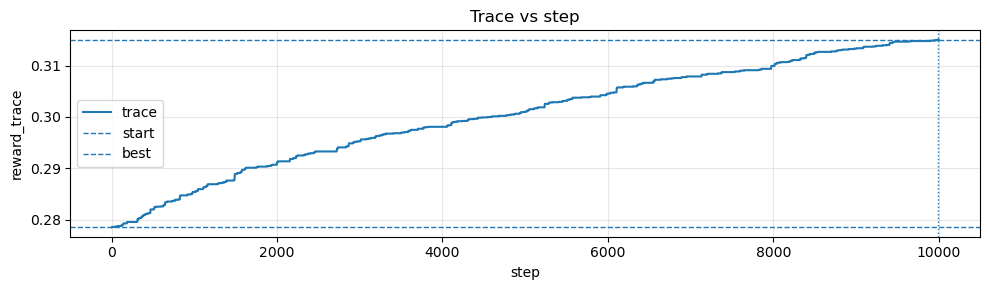

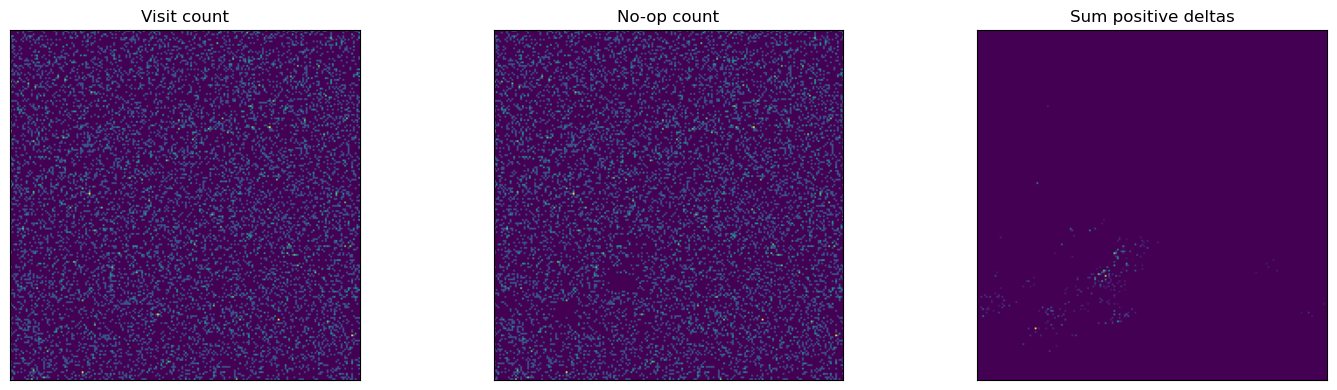

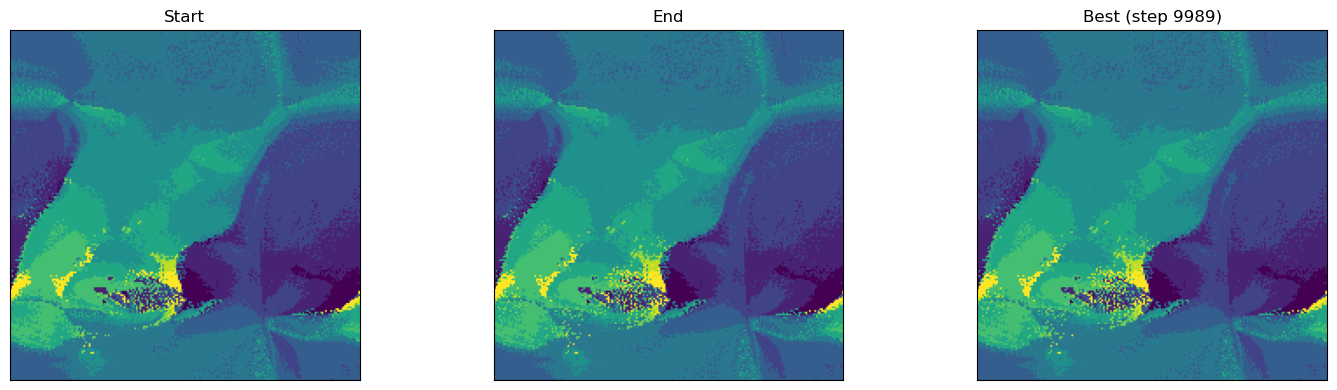

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
plot_trace(art, ax=ax)
plt.tight_layout()
plt.show()

plot_heatmaps(art)
plt.tight_layout()
plt.show()

plot_bin_snapshots(art, env.H, env.W)
plt.tight_layout()
plt.show()


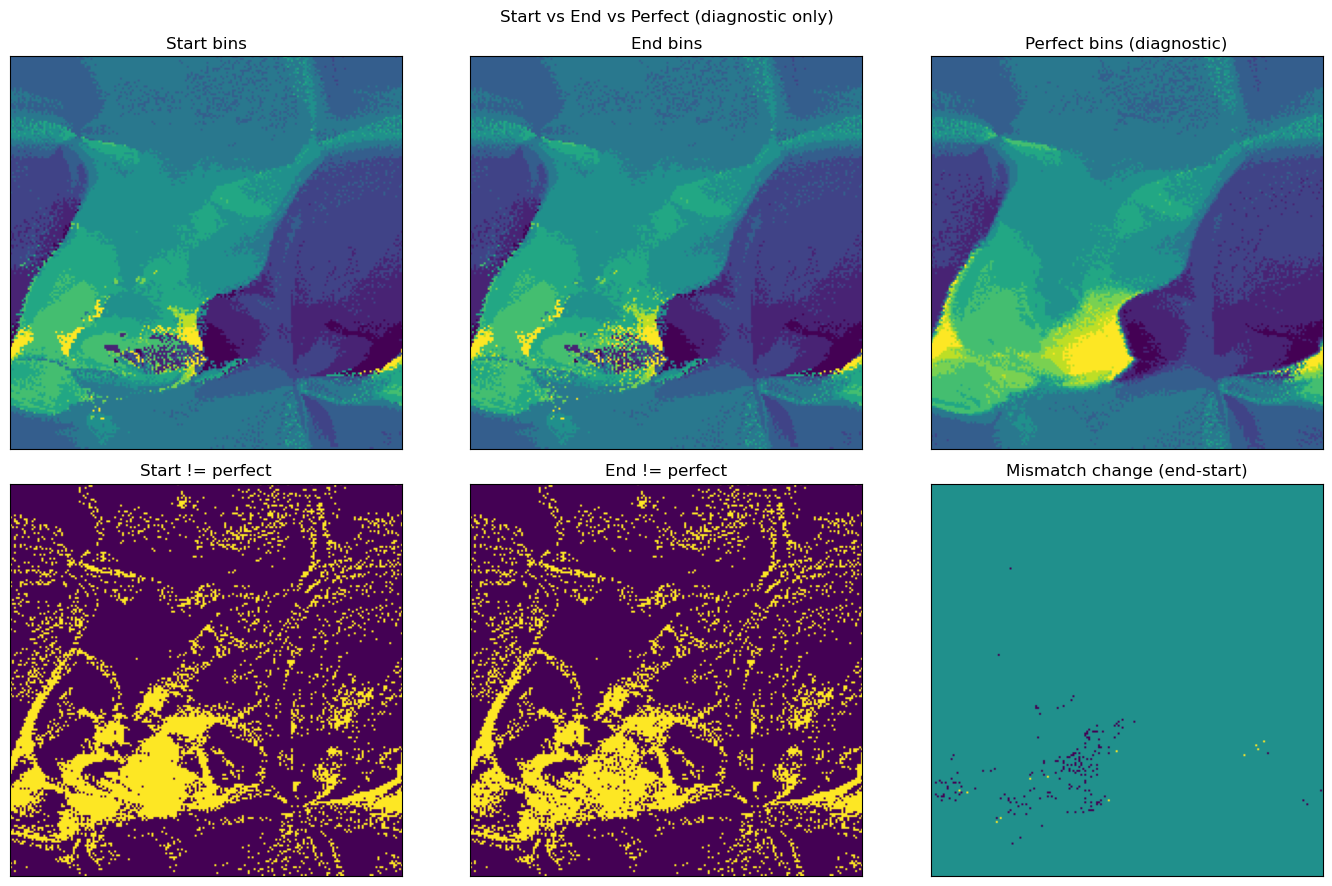

Match to perfect: start=0.795, end=0.799, Δ=+0.004


In [9]:
start_bins = som.initial_bins.copy()
end_bins = som.current_bins.copy()
perfect_bins = get_perfect_bins()
plot_bins_triptych(
    start_bins=start_bins,
    end_bins=end_bins,
    perfect_bins=perfect_bins,
    H=H, W=W, K=K,
    title="Start vs End vs Perfect (diagnostic only)"
)


### Need to Eval the perfect SOM

In [14]:
import pickle
ROOT = "data"  # or your project root
NPZ_PATH = os.path.join(ROOT, "correlations_dl", "npairs_compact.npz")

INITIAL_NODE_BINS_PATH = os.path.join(ROOT, "nodes_labels_initial_fc_200_ext.npy")
NODE_INDICES_PHOTO_PATH = os.path.join(ROOT, "node_indices_fc.npy")

# user-specified reference labels path
REFERENCE_LABELS_PATH = os.path.join(ROOT, "reference_labels_fc_fc.npy")

# optional "true TreeCorr column" pickles
DD_PKL = os.path.join(ROOT, "correlations_dl", "dd.pkl")
DR_PKL = os.path.join(ROOT, "correlations_dl", "dr.pkl")
RD_PKL = os.path.join(ROOT, "correlations_dl", "rd.pkl")
RR_PKL = os.path.join(ROOT, "correlations_dl", "rr.pkl")

# SOM shape
H, W = 200, 200
N_NODES = H * W
K = 11

# Trajectory settings
GOOD_STEPS = 2500
BAD_STEPS = 2500
CHECK_EVERY = 250  # compute true TreeCorr at these step indices
RNG_SEED = 42


In [15]:
have_tc = all(os.path.exists(p) for p in (DD_PKL, DR_PKL, RD_PKL, RR_PKL))
print("Have TreeCorr pickles:", have_tc)

if have_tc:
    with open(DD_PKL, "rb") as f: dd_tc = pickle.load(f)
    with open(DR_PKL, "rb") as f: dr_tc = pickle.load(f)
    with open(RD_PKL, "rb") as f: rd_tc = pickle.load(f)
    with open(RR_PKL, "rb") as f: rr_tc = pickle.load(f)

    import treecorr

    def treecorr_trace_from_columns(
        current_bins: np.ndarray,
        dd_cols, dr_cols, rd_cols, rr_cols,
        num_bins=11,
        min_sep=0.01, max_sep=0.1, sep_units="degrees", nbins=1
    ):
        bins_nodes = [np.where(current_bins == i)[0] for i in range(num_bins)]
        xi_bins = np.zeros((num_bins, num_bins), dtype=np.float64)

        for j in range(num_bins):      # ref bin
            for i in range(num_bins):  # phot bin
                dd_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)
                dr_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)
                rd_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)
                rr_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)

                for k in bins_nodes[i]:
                    dd_tot.__iadd__(dd_cols[j, k])
                    dr_tot.__iadd__(dr_cols[j, k])
                    rd_tot.__iadd__(rd_cols[j, k])
                    rr_tot.__iadd__(rr_cols[j, k])

                dd_tot.finalize(); dr_tot.finalize(); rd_tot.finalize(); rr_tot.finalize()
                xi = dd_tot.calculateXi(rr=rr_tot, dr=dr_tot, rd=rd_tot)[0]
                xi_bins[i, j] = float(np.ravel(xi)[0])

        return float(np.trace(xi_bins)), xi_bins


Have TreeCorr pickles: True


In [16]:
import numpy as np

def set_bins_in_backend(som, bins_1d):
    # hard reset then apply bins directly (fastest)
    som.reset_to_initial()
    som.current_bins[:] = np.asarray(bins_1d, dtype=np.int32)
    som._build_caches()  # rebuild sums/counts

bins_start   = np.asarray(initial_node_bins, dtype=np.int32)
bins_perfect = np.asarray(perfect_bins, dtype=np.int32)

# Backend rewards
set_bins_in_backend(som, bins_start)
r_start_fast = som.reward_trace()

set_bins_in_backend(som, bins_perfect)
r_perf_fast  = som.reward_trace()

print("FAST reward_trace:")
print("  start  :", r_start_fast)
print("  perfect:", r_perf_fast)
print("  delta  :", r_perf_fast - r_start_fast)

# True TreeCorr rewards (if available)
if have_tc:
    tc_start, _ = treecorr_trace_from_columns(bins_start,  dd_tc, dr_tc, rd_tc, rr_tc, num_bins=som.K)
    tc_perf,  _ = treecorr_trace_from_columns(bins_perfect, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=som.K)

    print("\nTRUE TreeCorr trace:")
    print("  start  :", tc_start)
    print("  perfect:", tc_perf)
    print("  delta  :", tc_perf - tc_start)

FAST reward_trace:
  start  : 0.2785188710136125
  perfect: 0.3521075842980866
  delta  : 0.07358871328447408

TRUE TreeCorr trace:
  start  : 0.27851887101361134
  perfect: 0.35210758429808525
  delta  : 0.07358871328447392


In [17]:
import numpy as np

def true_best_bin_for_node(current_bins, node, K, dd_tc, dr_tc, rd_tc, rr_tc):
    base = current_bins.copy()
    base_trace, _ = treecorr_trace_from_columns(base, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K)

    oldb = int(base[node])
    bestb = oldb
    bestd = 0.0

    for newb in range(K):
        if newb == oldb:
            continue
        test = base.copy()
        test[node] = newb
        tr, _ = treecorr_trace_from_columns(test, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K)
        d = tr - base_trace
        if d > bestd:
            bestd = float(d)
            bestb = int(newb)

    return bestb, bestd, float(base_trace)

# choose a consistent base state to test from (start or perfect)
base_bins = bins_start.copy()

# pick eligible nodes only (non-empty)
eligible_nodes = np.flatnonzero(som.node_gal_counts > 0)
rng = np.random.default_rng(0)
test_nodes = rng.choice(eligible_nodes, size=30, replace=False)

# Compare
agreements = 0
rows = []

for node in test_nodes:
    # backend
    set_bins_in_backend(som, base_bins)
    b_fast, d_fast = som.best_bin_for_node(int(node))

    # true
    if have_tc:
        b_true, d_true, base_true = true_best_bin_for_node(base_bins, int(node), som.K, dd_tc, dr_tc, rd_tc, rr_tc)
        agreements += int(b_fast == b_true)
        rows.append((int(node), int(base_bins[node]), b_fast, d_fast, b_true, d_true))

print(f"Agreement rate (best bin): {agreements}/{len(test_nodes)} = {agreements/len(test_nodes):.3f}")

# show a few disagreements
if have_tc:
    bad = [r for r in rows if r[2] != r[4]]
    print("Num disagreements:", len(bad))
    print("Example rows: (node, old, fast_best, fast_d, true_best, true_d)")
    for r in bad[:10]:
        print(r)


Agreement rate (best bin): 30/30 = 1.000
Num disagreements: 0
Example rows: (node, old, fast_best, fast_d, true_best, true_d)


bestd stats:
  frac noop (<=0): 0.532
  mean bestd: 1.1175315532484983e-05
  median bestd: 0.0
  95th pct: 3.862811387706204e-05
  99th pct: 0.0002110142919849667


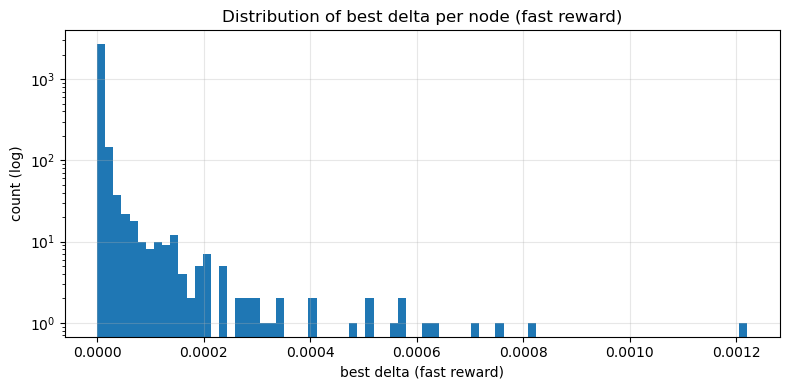

Suggested min_delta_trace (5th pct of positive deltas): 2.855232681620024e-07


In [18]:
import numpy as np
import matplotlib.pyplot as plt

def sample_best_deltas(som, base_bins, n_samples=2000, seed=1):
    rng = np.random.default_rng(seed)
    eligible = np.flatnonzero(som.node_gal_counts > 0)
    nodes = rng.choice(eligible, size=n_samples, replace=True)

    deltas = np.zeros(n_samples, dtype=np.float64)
    noops  = np.zeros(n_samples, dtype=bool)

    set_bins_in_backend(som, base_bins)

    for i, node in enumerate(nodes):
        bestb, bestd = som.best_bin_for_node(int(node))
        deltas[i] = bestd
        noops[i] = (bestd <= 0.0)

    return deltas, noops

base_bins = bins_start.copy()
deltas, noops = sample_best_deltas(som, base_bins, n_samples=3000, seed=123)

print("bestd stats:")
print("  frac noop (<=0):", noops.mean())
print("  mean bestd:", deltas.mean())
print("  median bestd:", np.median(deltas))
print("  95th pct:", np.percentile(deltas, 95))
print("  99th pct:", np.percentile(deltas, 99))

plt.figure(figsize=(8,4))
plt.hist(deltas, bins=80)
plt.yscale("log")
plt.xlabel("best delta (fast reward)")
plt.ylabel("count (log)")
plt.title("Distribution of best delta per node (fast reward)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# A simple threshold suggestion: ignore tiny deltas near numerical noise
min_delta = max(0.0, np.percentile(deltas[deltas > 0], 5)) if np.any(deltas > 0) else 0.0
print("Suggested min_delta_trace (5th pct of positive deltas):", float(min_delta))


From PERFECT (min_delta=0): applied: 2775 noop: 7225 final-start: 0.012436939945279946


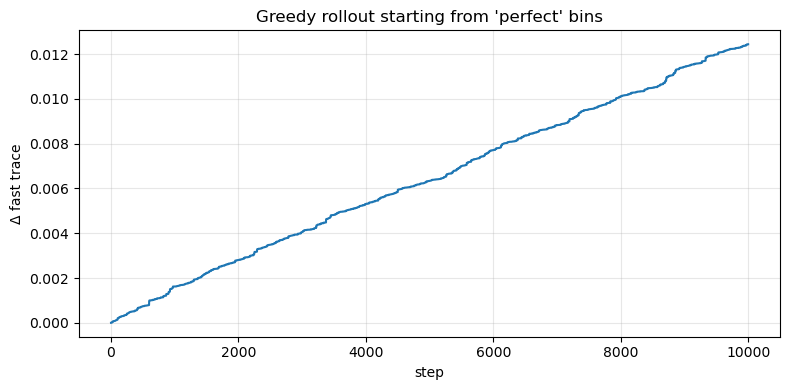

From PERFECT (min_delta=2e-05): applied: 114 noop: 9886 final-start: 0.0053096753682858044


In [24]:
import numpy as np

def rollout_greedy_from_bins(som, start_bins, steps=5000, min_delta_trace=0.0, seed=0):
    rng = np.random.default_rng(seed)
    eligible = np.flatnonzero(som.node_gal_counts > 0)

    set_bins_in_backend(som, start_bins)
    trace = [som.reward_trace()]
    n_apply = 0
    n_noop  = 0

    for t in range(steps):
        node = int(rng.choice(eligible))
        bestb, bestd = som.best_bin_for_node(node)
        oldb = int(som.current_bins[node])

        if bestd >= min_delta_trace and bestb != oldb:
            som._rank1_move(node, oldb, bestb)
            n_apply += 1
        else:
            n_noop += 1

        trace.append(som.reward_trace())

    return np.array(trace), n_apply, n_noop

# Try starting from your "perfect" bins
trace0, n_apply0, n_noop0 = rollout_greedy_from_bins(
    som, bins_perfect, steps=10000, min_delta_trace=0.0, seed=0
)

print("From PERFECT (min_delta=0): applied:", n_apply0, "noop:", n_noop0, "final-start:", trace0[-1]-trace0[0])

import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.plot(trace0 - trace0[0])
plt.xlabel("step")
plt.ylabel("Δ fast trace")
plt.title("Greedy rollout starting from 'perfect' bins")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Repeat with a threshold (plug your suggested min_delta here)
min_delta = 0.00002  # replace with suggested value from Cell 3
trace1, n_apply1, n_noop1 = rollout_greedy_from_bins(
    som, bins_perfect, steps=10000, min_delta_trace=min_delta, seed=0
)
print(f"From PERFECT (min_delta={min_delta}): applied:", n_apply1, "noop:", n_noop1, "final-start:", trace1[-1]-trace1[0])


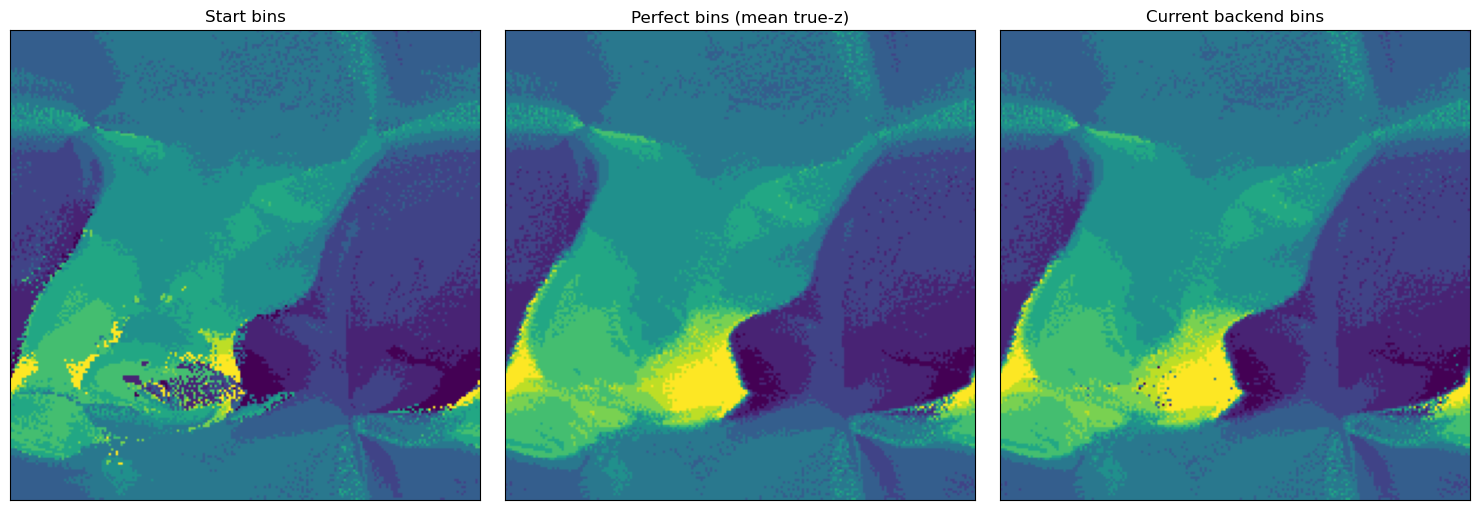

In [25]:
import matplotlib.pyplot as plt
import numpy as np

H, W, K = som.H, som.W, som.K
def bins_to_image(bins_1d): return np.asarray(bins_1d, dtype=np.int32).reshape(H, W)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(bins_to_image(bins_start),   vmin=0, vmax=K-1); axs[0].set_title("Start bins")
axs[1].imshow(bins_to_image(bins_perfect), vmin=0, vmax=K-1); axs[1].set_title("Perfect bins (mean true-z)")
axs[2].imshow(bins_to_image(som.get_state()), vmin=0, vmax=K-1); axs[2].set_title("Current backend bins")

for ax in axs: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
